# Firing rate and sniff rate

Does a unit's firing rate follow the animal's sniff rate, and is the relationship a straight line? Scores come
from `sniff-raster-python/sniff_rate_model.py` (`E:/cbm-odor/sniff/sniff_rate_model.csv`). Its docstring has the
details.

- **Bins:** time is cut into 250 ms bins. Each bin has the unit's z-scored spike count and the sniff rate (the
  time-weighted mean of 1 / inhalation interval, from the MATLAB sniff params).
- **The confound:** sniff rate goes up with running and changes with epoch, so a unit tuned to running or to the
  task would also look tuned to sniffing. Each unit is therefore fit with:
  - `cov`: epoch + body speed (SLEAP centroid, spline) + time in session (spline, absorbs drift)
  - `cov_lin`: `cov` + a straight line in sniff rate
  - `cov_spl`: `cov` + a natural cubic spline in sniff rate (4 df)
- **Scoring:** cross-validated R² on held-out 30 s blocks. `dr2` is what sniff rate adds to `cov`, so a curve only
  wins if it predicts held-out time better than a line.
- **Significance:** `p_spl` and `p_lin` come from circularly shifting the sniff rate against everything else
  (200 shifts, at least 30 s apart). This breaks the alignment with sniffing but keeps the unit's relation to speed,
  epoch and drift.

Units with fewer than 100 spikes in usable bins are left out. Sessions without sniff params (9004, and a few others)
aren't included.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = 'E:/cbm-odor/'
KEYS = ['mouse', 'session', 'region', 'cluster']
EPOCHS = ['search', 'retrieval', 'consumption']
EPOCH_COLORS = dict(search='#2a78d6', retrieval='#eb6834', consumption='#1baf7a')
REGION_COLORS = dict(ob='#2a78d6', hc='#eb6834')
REGION_NAMES = dict(ob='OB', hc='CA1')
ALPHA = 0.05
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '0.92', 'grid.linewidth': 0.6, 'axes.axisbelow': True})

d = pd.read_csv(ROOT + 'sniff/sniff_rate_model.csv', dtype={'mouse': str, 'session': str})
tun = np.load(ROOT + 'sniff/sniff_rate_tuning.npz')
assert (tun['cluster'] == d['cluster']).all() and (tun['session'] == d['session']).all()
curves, edges = tun['curves'], tun['edges']
hz = edges[:-1] + 0.5
sess = pd.read_csv(ROOT + 'sniff/sniff_rate_sessions.csv', dtype={'mouse': str, 'session': str})

read = lambda f, cols: pd.read_csv(ROOT + f, dtype={'mouse': str, 'session': str})[KEYS + cols]
d = (d.merge(read('sniff/mt_cell_inventory.csv', ['cell_type']), on=KEYS, how='left')
      .merge(read('sniff/sniff_locking.csv', ['info_p']).rename(columns={'info_p': 'sniff_lock_p'}), on=KEYS, how='left')
      .merge(read('theta/theta_locking.csv', ['mrl_p']).rename(columns={'mrl_p': 'theta_p'}), on=KEYS, how='left'))
d['sniff_locked'] = np.where(d['sniff_lock_p'].isna(), np.nan, d['sniff_lock_p'] < ALPHA)
d['theta_locked'] = np.where(d['theta_p'].isna(), np.nan, d['theta_p'] < ALPHA)
d['sig'] = d['p_spl'] < ALPHA
print(f"{len(sess)} sessions, {sess['mouse'].nunique()} mice")
print(d.groupby('region').size().rename(index=REGION_NAMES).to_string())

122 sessions, 8 mice
region
CA1    2971
OB     1968


## Sniff rate and behavior

How sniff rate differs between epochs, and how strongly it tracks running speed within a session. This is why the
covariates are needed.

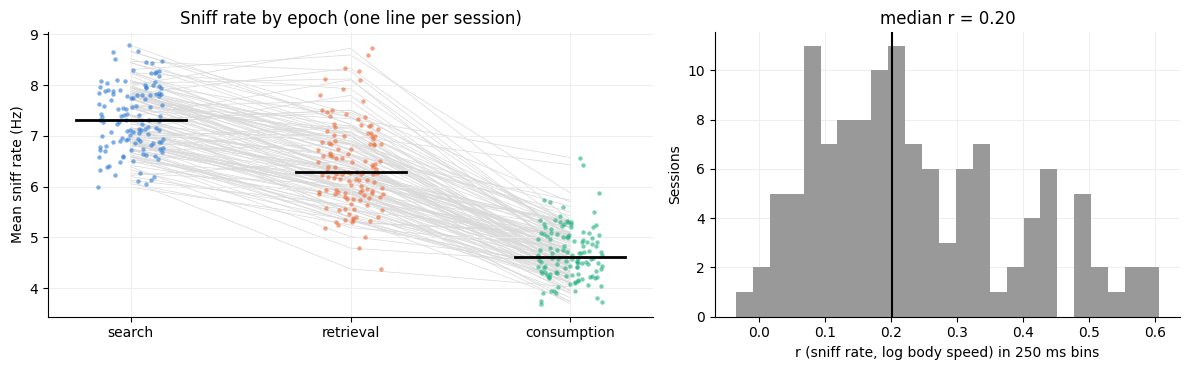

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axs[0]
for k, e in enumerate(EPOCHS):
    v = sess[f'sniff_hz_{e}']
    ax.scatter(k + np.random.default_rng(k).uniform(-0.15, 0.15, len(v)), v, s=10, color=EPOCH_COLORS[e], alpha=0.6,
               linewidths=0)
    ax.plot([k - 0.25, k + 0.25], [v.median()] * 2, color='k', lw=2)
for _, s in sess.iterrows():
    ax.plot(range(3), [s[f'sniff_hz_{e}'] for e in EPOCHS], color='0.85', lw=0.5, zorder=0)
ax.set(xticks=range(3), xticklabels=EPOCHS, ylabel='Mean sniff rate (Hz)', title='Sniff rate by epoch (one line per session)')
axs[1].hist(sess['r_sniff_logspeed'], 25, color='0.6')
axs[1].axvline(sess['r_sniff_logspeed'].median(), color='k', lw=1.5)
axs[1].set(xlabel='r (sniff rate, log body speed) in 250 ms bins', ylabel='Sessions',
           title=f"median r = {sess['r_sniff_logspeed'].median():.2f}")
fig.tight_layout()

## Does sniff rate explain firing beyond behavior?

Left: how many units sniff rate explains significantly beyond the covariates (spline model). Right: how much it
adds (`dr2_spl`, the gain in cross-validated R²). Rates are binned at 250 ms, so the R² values are small for every
model. Compare them with `cv_r2_cov`, the covariates on their own, printed below.

,n,sig_spl,sig_lin,cv_r2_cov,dr2_lin,dr2_spl,r_sniff
region,,,,,,,
CA1,2971,0.7449,0.5678,0.0645,0.0006,0.0020,0.0410
OB,1968,0.9228,0.8547,0.0358,0.0105,0.0137,0.0743


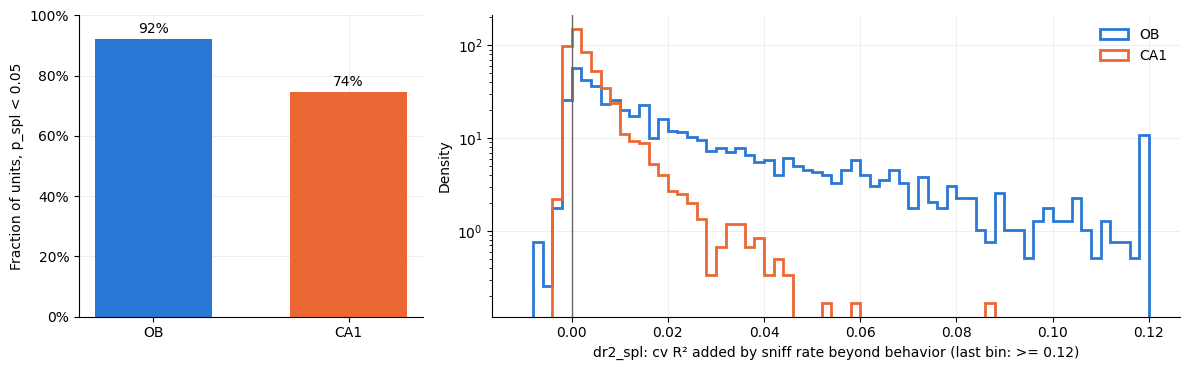

In [3]:
summ = d.groupby('region').agg(n=('cluster', 'size'), sig_spl=('sig', 'mean'), sig_lin=('p_lin', lambda p: (p < ALPHA).mean()),
                               cv_r2_cov=('cv_r2_cov', 'median'), dr2_lin=('dr2_lin', 'median'), dr2_spl=('dr2_spl', 'median'),
                               r_sniff=('r_sniff', 'median')).rename(index=REGION_NAMES)
display(summ.round(4))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 2]))
x = np.arange(2)
axs[0].bar(x, [d.loc[d.region == r, 'sig'].mean() for r in ['ob', 'hc']], color=[REGION_COLORS[r] for r in ['ob', 'hc']],
           width=0.6)
for xi, r in zip(x, ['ob', 'hc']):
    axs[0].text(xi, d.loc[d.region == r, 'sig'].mean() + 0.02, f"{d.loc[d.region == r, 'sig'].mean():.0%}", ha='center')
axs[0].set(xticks=x, xticklabels=['OB', 'CA1'], ylim=(0, 1), ylabel='Fraction of units, p_spl < 0.05')
axs[0].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
bins = np.linspace(-0.01, 0.12, 66)  # the last bin collects everything above
for r in ['ob', 'hc']:
    axs[1].hist(d.loc[d.region == r, 'dr2_spl'].clip(bins[0], bins[-1]), bins, histtype='step', lw=2,
                color=REGION_COLORS[r], label=REGION_NAMES[r], density=True)
axs[1].axvline(0, color='0.4', lw=1)
axs[1].set(xlabel='dr2_spl: cv R² added by sniff rate beyond behavior (last bin: >= 0.12)', ylabel='Density', yscale='log')
axs[1].legend(frameon=False)
fig.tight_layout()

## Line or curve?

`nonlin_gain` is how much better the spline predicts held-out time than the straight line, both on top of the
covariates. It is positive when the relationship bends: it saturates, has a peak, or changes slope. Only units
significant for the spline are shown.

,count,25%,50%,75%
region,,,,
CA1,2213.0,0.0004,0.0012,0.0032
OB,1816.0,0.0001,0.0012,0.0036


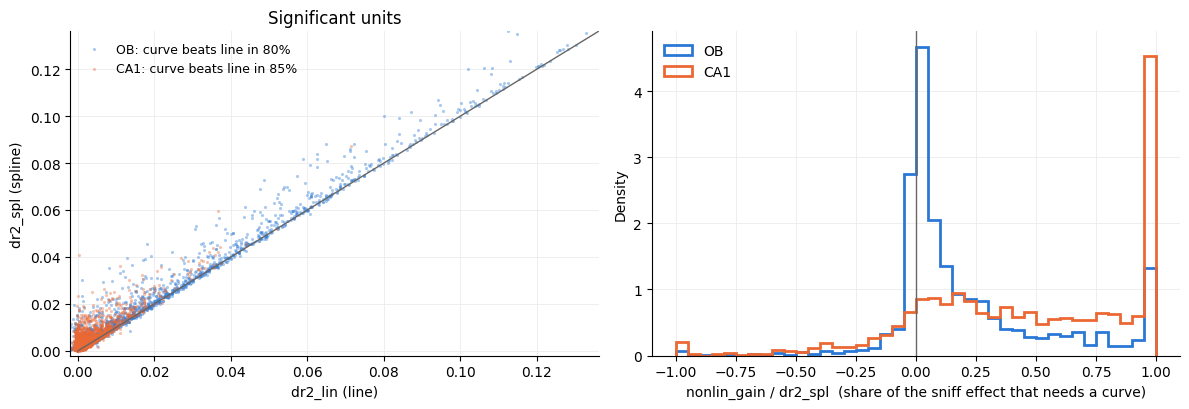

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
s = d[d['sig']]
for r in ['ob', 'hc']:
    g = s[s.region == r]
    axs[0].scatter(g['dr2_lin'], g['dr2_spl'], s=5, color=REGION_COLORS[r], alpha=0.4, linewidths=0, rasterized=True,
                   label=f"{REGION_NAMES[r]}: curve beats line in {(g['nonlin_gain'] > 0).mean():.0%}")
lim = np.nanpercentile(s[['dr2_lin', 'dr2_spl']], 99.5)
axs[0].plot([0, lim], [0, lim], color='0.4', lw=1)
axs[0].set(xlim=(-0.002, lim), ylim=(-0.002, lim), xlabel='dr2_lin (line)', ylabel='dr2_spl (spline)',
           title='Significant units')
axs[0].legend(frameon=False, fontsize=9, loc='upper left')
rel = s['nonlin_gain'] / s['dr2_spl'].where(s['dr2_spl'] > 0)
for r in ['ob', 'hc']:
    axs[1].hist(rel[s.region == r].clip(-1, 1), np.linspace(-1, 1, 41), histtype='step', lw=2, color=REGION_COLORS[r],
                label=REGION_NAMES[r], density=True)
axs[1].axvline(0, color='0.4', lw=1)
axs[1].set(xlabel='nonlin_gain / dr2_spl  (share of the sniff effect that needs a curve)', ylabel='Density')
axs[1].legend(frameon=False)
fig.tight_layout()
s.groupby('region')['nonlin_gain'].describe()[['count', '25%', '50%', '75%']].rename(index=REGION_NAMES).round(4)

## Shape of the relationship

Partial tuning curves: the mean residual z after removing the covariates, in 1 Hz sniff-rate bins. For each
region, significant units are split by the sign of their partial slope. Below, each row is one significant unit's
partial curve, scaled to its own maximum |z| and sorted by the sniff rate where it peaks. Only 2-11 Hz is shown, where nearly all of
the time is. Monotonic units form the two edges of the heatmap, and units with a peak in the middle form the diagonal.

C:\Users\smearlab\AppData\Local\Temp\ipykernel_31016\2524266833.py:6: RuntimeWarning: Mean of empty slice
  mu, se = np.nanmean(part[m], 0), np.nanstd(part[m], 0) / np.sqrt(np.isfinite(part[m]).sum(0))
C:\ProgramData\anaconda3\envs\sldata\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


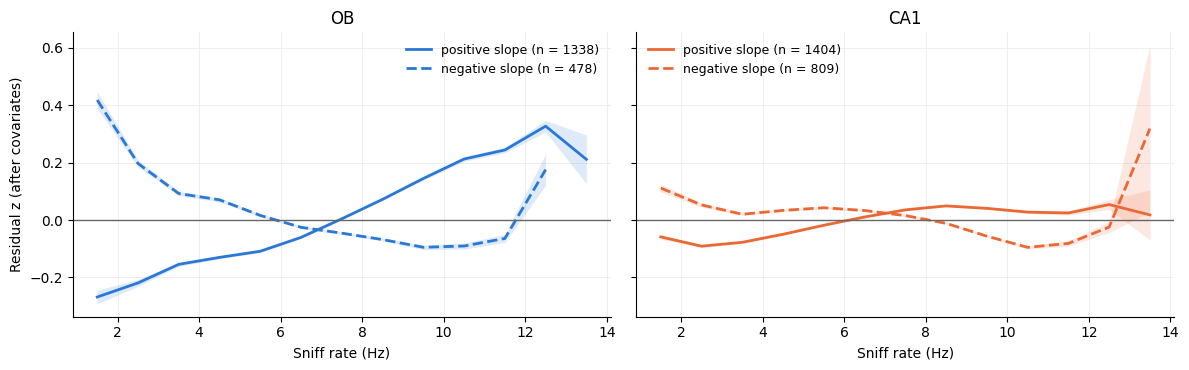

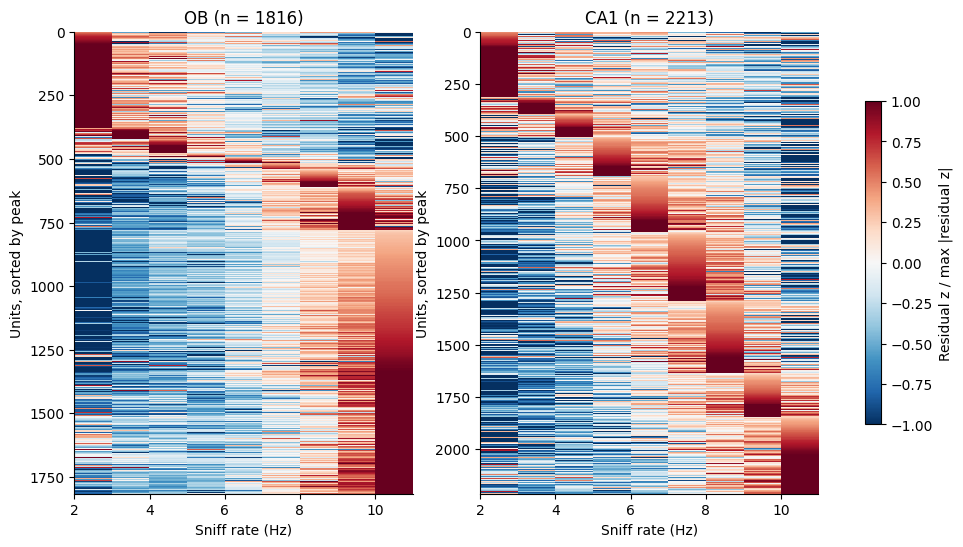

In [5]:
part = curves[:, 1]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, r in zip(axs, ['ob', 'hc']):
    for sign, ls, lab in [(1, '-', 'positive slope'), (-1, '--', 'negative slope')]:
        m = (d.region == r).to_numpy() & d['sig'].to_numpy() & (np.sign(d['slope_partial_hz']).to_numpy() == sign)
        mu, se = np.nanmean(part[m], 0), np.nanstd(part[m], 0) / np.sqrt(np.isfinite(part[m]).sum(0))
        ax.plot(hz, mu, ls, color=REGION_COLORS[r], lw=2, label=f'{lab} (n = {m.sum()})')
        ax.fill_between(hz, mu - 1.96 * se, mu + 1.96 * se, color=REGION_COLORS[r], alpha=0.15, lw=0)
    ax.axhline(0, color='0.4', lw=1)
    ax.set(title=REGION_NAMES[r], xlabel='Sniff rate (Hz)')
    ax.legend(frameon=False, fontsize=9)
axs[0].set_ylabel('Residual z (after covariates)')
fig.tight_layout()

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, r in zip(axs, ['ob', 'hc']):
    m = (d.region == r).to_numpy() & d['sig'].to_numpy()
    c = part[m][:, 1:10]  # 2-11 Hz: the outer bins hold little time, so they are noisy and dominate a max-scaling
    ok = np.isfinite(c).sum(1) >= 7
    c = c[ok] / np.nanmax(np.abs(c[ok]), 1, keepdims=True)
    order = np.argsort([np.nanargmax(row) + 0.01 * np.nanmax(row) for row in c])
    im = ax.imshow(c[order], aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest',
                   extent=(edges[1], edges[10], len(c), 0))
    ax.set(title=f'{REGION_NAMES[r]} (n = {len(c)})', xlabel='Sniff rate (Hz)', ylabel='Units, sorted by peak')
    ax.grid(False)
fig.colorbar(im, ax=axs, label='Residual z / max |residual z|', shrink=0.7);

## Direction, and whether it holds in every epoch

Partial slope (z per Hz, beyond covariates) by region. Then, for the significant units, the slope fit within each
epoch on its own. If the relationship were only the epoch difference in sniffing in disguise, it would vanish within
epochs. During consumption, breathing locks to licking, so that epoch may behave differently.

,OB,CA1
same sign as overall,,
search,0.97,0.86
retrieval,0.68,0.59
consumption,0.65,0.63


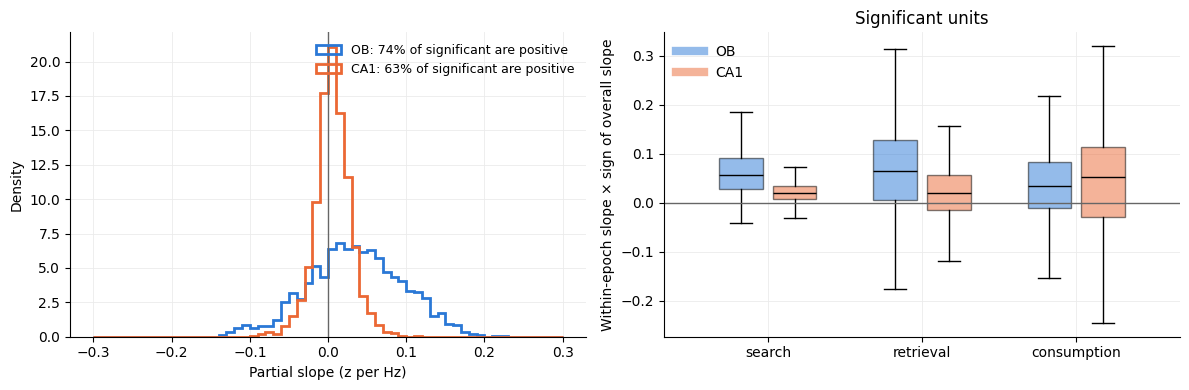

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(-0.3, 0.3, 61)  # the end bins collect the tails
for r in ['ob', 'hc']:
    g = d[d.region == r]
    axs[0].hist(g['slope_partial_hz'].clip(bins[0], bins[-1]), bins, histtype='step', lw=2, color=REGION_COLORS[r],
                density=True, label=f"{REGION_NAMES[r]}: {(g.loc[g.sig, 'slope_partial_hz'] > 0).mean():.0%} of significant are positive")
axs[0].axvline(0, color='0.4', lw=1)
axs[0].set(xlabel='Partial slope (z per Hz)', ylabel='Density')
axs[0].legend(frameon=False, fontsize=9)
ax = axs[1]
w = 0.35
for k, r in enumerate(['ob', 'hc']):
    g = d[(d.region == r) & d.sig]
    # slope within epoch, signed by the unit's overall partial slope: > 0 means the same direction as overall
    sgn = np.sign(g['slope_partial_hz'])
    vals = [(g[f'slope_{e}_hz'] * sgn).dropna() for e in EPOCHS]
    bp = ax.boxplot(vals, positions=np.arange(3) + (k - 0.5) * w, widths=w * 0.8, showfliers=False, patch_artist=True,
                    medianprops=dict(color='k'))
    for b in bp['boxes']:
        b.set(facecolor=REGION_COLORS[r], alpha=0.5)
    ax.plot([], [], color=REGION_COLORS[r], lw=6, alpha=0.5, label=REGION_NAMES[r])
ax.axhline(0, color='0.4', lw=1)
ax.set(xticks=range(3), xticklabels=EPOCHS, ylabel='Within-epoch slope × sign of overall slope',
       title='Significant units')
ax.legend(frameon=False)
fig.tight_layout()
pd.DataFrame({REGION_NAMES[r]: {e: (np.sign(d.loc[(d.region == r) & d.sig, f'slope_{e}_hz'])
                                    == np.sign(d.loc[(d.region == r) & d.sig, 'slope_partial_hz'])).mean() for e in EPOCHS}
              for r in ['ob', 'hc']}).rename_axis('same sign as overall').round(2)

## By unit type

Fraction significant, and the median `dr2_spl` and partial slope, by type. As in the epoch-rate analysis, mice
contribute different mixes of types, so each comparison is repeated within mouse. The type difference is computed in
each mouse that has at least 10 units of both types, and the Wilcoxon test is across those mice. With 5 mice the
smallest possible two-sided p is 0.0625, so for the OB comparisons the 'mice same sign' column says more than p.

In [7]:
groupings = [('ob', 'cell_type', 'tufted', 'mitral', 'OB tufted vs mitral'),
             ('ob', 'sniff_locked', 1.0, 0.0, 'OB sniff-locked vs not'),
             ('hc', 'sniff_locked', 1.0, 0.0, 'CA1 sniff-locked vs not'),
             ('hc', 'theta_locked', 1.0, 0.0, 'CA1 theta-locked vs not'),
             ('hc', 'group', 'good', 'mua', 'CA1 good vs mua')]
rows = []
for r, col, a, b, lab in groupings:
    g = d[(d.region == r) & d[col].notna()]
    for metric in ['sig', 'dr2_spl', 'slope_partial_hz']:
        agg = 'mean' if metric == 'sig' else 'median'
        pooled = [g.loc[g[col] == v, metric].agg(agg) for v in (a, b)]
        per = g.groupby(['mouse', col])[metric].agg(agg).unstack(col)
        cnt = g.groupby(['mouse', col]).size().unstack(col)
        ok = (cnt[[a, b]] >= 10).all(axis=1)
        diff = (per[a] - per[b])[ok]
        p = stats.wilcoxon(diff)[1] if len(diff) >= 5 and diff.abs().sum() > 0 else np.nan
        rows.append({'comparison': lab, 'metric': metric, 'A': pooled[0], 'B': pooled[1], 'pooled A-B': pooled[0] - pooled[1],
                     'mice': int(ok.sum()), 'mice same sign': int((np.sign(diff) == np.sign(pooled[0] - pooled[1])).sum()),
                     'within-mouse median A-B': diff.median(), 'Wilcoxon p': p})
pd.DataFrame(rows).set_index(['comparison', 'metric']).round(4)

A       B  pooled A-B  mice  \
comparison              metric                                               
OB tufted vs mitral     sig               0.9588  0.9226      0.0361     5   
                        dr2_spl           0.0253  0.0109      0.0144     5   
                        slope_partial_hz  0.0676 -0.0240      0.0916     5   
OB sniff-locked vs not  sig               0.9359  0.8423      0.0937     4   
                        dr2_spl           0.0154  0.0050      0.0104     4   
                        slope_partial_hz  0.0442 -0.0130      0.0571     4   
CA1 sniff-locked vs not sig               0.8475  0.6665      0.1810     8   
                        dr2_spl           0.0039  0.0010      0.0029     8   
                        slope_partial_hz  0.0086  0.0041      0.0046     8   
CA1 theta-locked vs not sig               0.7696  0.6102      0.1594     8   
                        dr2_spl           0.0023  0.0006      0.0017     8   
                        slope_partial_hz  0.0061  0.0020      0.0041     8   
CA1 good vs mua         sig               0.7396  0.7464     -0.0068     8   
                        dr2_spl           0.0021  0.0019      0.0002     8   
                        slope_partial_hz  0.0056  0.0054      0.0002     8   

                                          mice same sign  \
comparison              metric                             
OB tufted vs mitral     sig                            4   
                        dr2_spl                        3   
                        slope_partial_hz               5   
OB sniff-locked vs not  sig                            3   
                        dr2_spl                        4   
                        slope_partial_hz               4   
CA1 sniff-locked vs not sig                            8   
                        dr2_spl                        8   
                        slope_partial_hz               8   
CA1 theta-locked vs not sig                            7   
                        dr2_spl                        7   
                        slope_partial_hz               7   
CA1 good vs mua         sig                            5   
                        dr2_spl                        5   
                        slope_partial_hz               4   

                                          within-mouse median A-B  Wilcoxon p  
comparison              metric                                                 
OB tufted vs mitral     sig                                0.0592      0.3125  
                        dr2_spl                            0.0066      0.3125  
                        slope_partial_hz                   0.0735      0.0625  
OB sniff-locked vs not  sig                                0.0819         NaN  
                        dr2_spl                            0.0093         NaN  
                        slope_partial_hz                   0.0381         NaN  
CA1 sniff-locked vs not sig                                0.1421      0.0078  
                        dr2_spl                            0.0019      0.0078  
                        slope_partial_hz                   0.0037      0.0078  
CA1 theta-locked vs not sig                                0.1554      0.0234  
                        dr2_spl                            0.0015      0.0156  
                        slope_partial_hz                   0.0046      0.0156  
CA1 good vs mua         sig                               -0.0223      1.0000  
                        dr2_spl                            0.0003      0.4609  
                        slope_partial_hz                  -0.0002      0.9453

## Every mouse

Fraction of significant units and the median partial slope in each mouse.

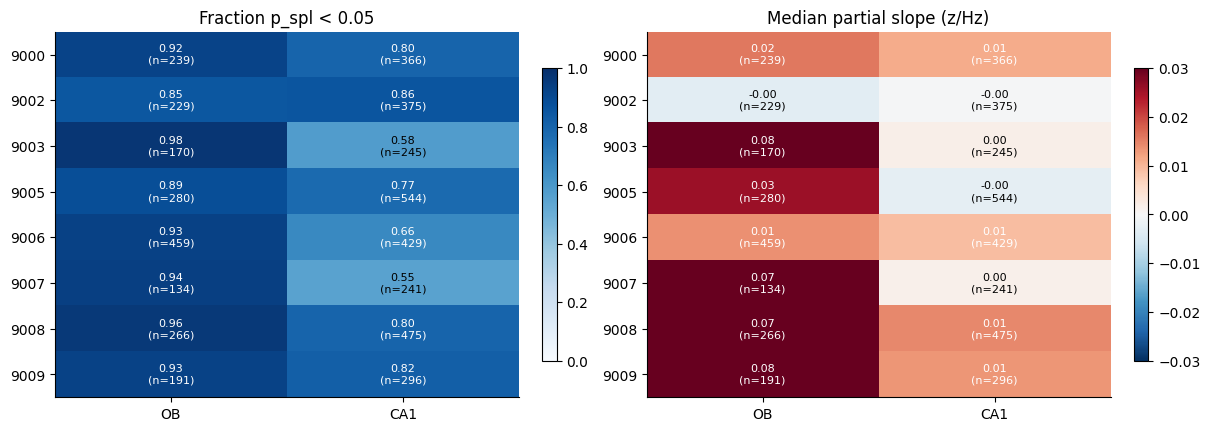

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), layout='constrained')
for ax, (metric, lab, cmap, vmin, vmax) in zip(axs, [('sig', 'Fraction p_spl < 0.05', 'Blues', 0, 1),
                                                     ('slope_partial_hz', 'Median partial slope (z/Hz)', 'RdBu_r', -0.03, 0.03)]):
    t = d.groupby(['mouse', 'region'])[metric].agg('mean' if metric == 'sig' else 'median').unstack('region')[['ob', 'hc']]
    n = d.groupby(['mouse', 'region']).size().unstack('region')[['ob', 'hc']]
    im = ax.imshow(t.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    for (i, j), v in np.ndenumerate(t.values):
        if np.isfinite(v):
            dark = (v - vmin) / (vmax - vmin) > 0.65 or (cmap == 'RdBu_r' and abs(v) > 0.6 * vmax)
            ax.text(j, i, f'{v:.2f}\n(n={int(n.values[i, j])})', ha='center', va='center', fontsize=8,
                    color='w' if dark else 'k')
    ax.set(xticks=[0, 1], xticklabels=['OB', 'CA1'], yticks=range(len(t)), yticklabels=t.index, title=lab)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)

## Example units

The three units per region with the largest `dr2_spl`. Raw tuning (mean z per sniff-rate bin) is shown in grey and
the partial tuning (after covariates) in color. Where the two differ, part of the raw relationship came from
running, epoch or drift.

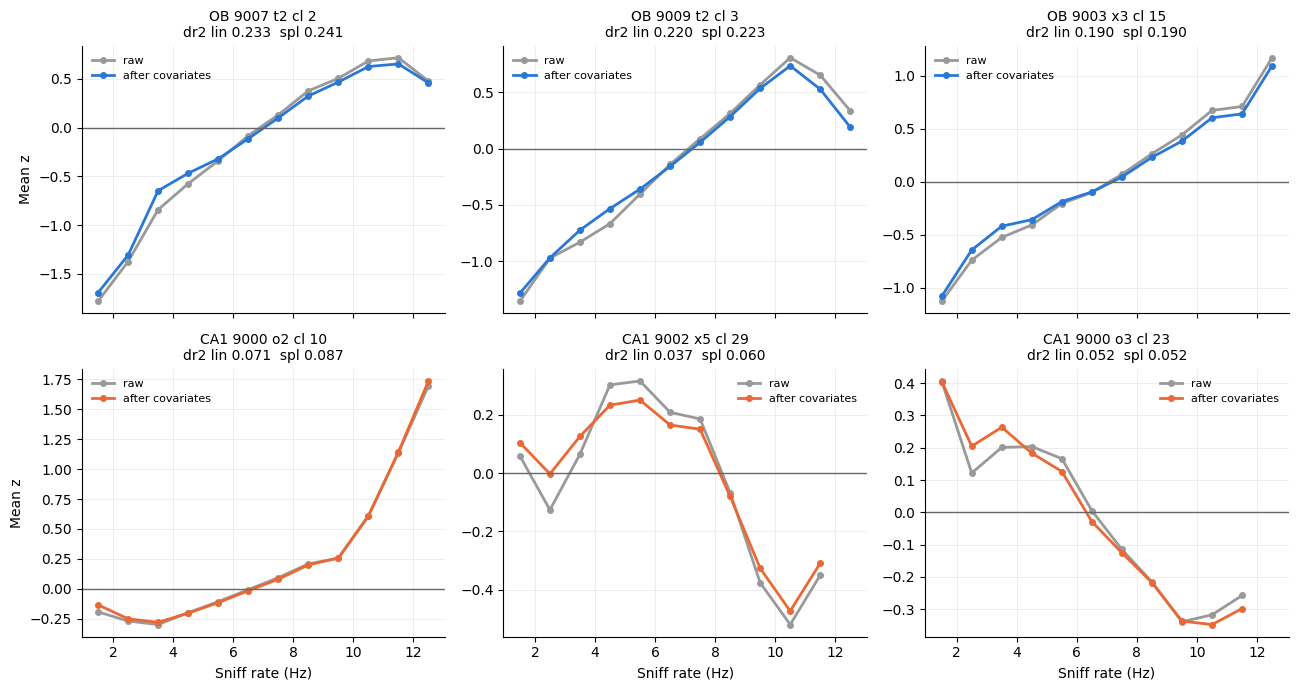

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for row, r in zip(axs, ['ob', 'hc']):
    idx = d[d.region == r].sort_values('dr2_spl', ascending=False).index[:3]
    for ax, i in zip(row, idx):
        u = d.loc[i]
        ax.plot(hz, curves[i, 0], color='0.6', lw=2, marker='o', ms=4, label='raw')
        ax.plot(hz, curves[i, 1], color=REGION_COLORS[r], lw=2, marker='o', ms=4, label='after covariates')
        ax.axhline(0, color='0.4', lw=1)
        ax.set_title(f"{REGION_NAMES[r]} {u.mouse} {u.session} cl {u.cluster}\n"
                     f"dr2 lin {u.dr2_lin:.3f}  spl {u.dr2_spl:.3f}", fontsize=10)
        ax.legend(frameon=False, fontsize=8)
for ax in axs[-1]:
    ax.set_xlabel('Sniff rate (Hz)')
for ax in axs[:, 0]:
    ax.set_ylabel('Mean z')
fig.tight_layout()